In [1]:
import matplotlib.image as mpimg
from glob import glob
import numpy as np
import pandas as pd

In [2]:
array_of_list_of_numbers = [[] for i in range(10)]
number_of_images = 105


for i in range(10):
    for filename in sorted(glob('TinyMNIST/train/' + str(i) + '/*.jpg'))[:number_of_images]:
        image = mpimg.imread(filename)
        array_of_list_of_numbers[i].append(image.flatten(order="f"))
print(f"The Dimension of Matrix is: {len(array_of_list_of_numbers)} * {len(array_of_list_of_numbers[0])}")
print(f"The Dimension of each Image Matrix is: {array_of_list_of_numbers[0][0].shape}")

The Dimension of Matrix is: 10 * 105
The Dimension of each Image Matrix is: (784,)


In [3]:
arr = np.empty([array_of_list_of_numbers[0][0].shape[0], number_of_images, 10])

for i in range(10):
    Ai = np.empty([784, number_of_images])
    for j in range(number_of_images):
        Ai[:, j] = array_of_list_of_numbers[i][j]
    arr[:, :, i] = Ai


In [4]:
def sort_by_number(filename: str) -> int:
    return int(filename.split(".")[0].split("_")[1])


sorted_arr = sorted(glob('TinyMNIST/test/test/*.jpg'), key=sort_by_number)
print(len(sorted_arr))
predicted = []

600


In [5]:
for i in range(arr.shape[-1]):
    print(arr[:, :, i].shape)

(784, 105)
(784, 105)
(784, 105)
(784, 105)
(784, 105)
(784, 105)
(784, 105)
(784, 105)
(784, 105)
(784, 105)


In [6]:
def LeastSqureQR(A, b):

    Q, R = np.linalg.qr(A)
    X = np.dot(np.dot(np.linalg.inv(R), Q.T), b)
    AX = np.dot(A, X)
    MinSquared = np.linalg.norm(b - AX)
    return MinSquared

In [7]:
for filename in sorted_arr:
    temp_arr = []
    image = mpimg.imread(filename)
    for i in range(arr.shape[-1]):
        A = arr[:, :, i]
        b = image.flatten(order="f")
        temp_arr.append(LeastSqureQR(A, b))
    predicted.append(temp_arr.index(min(temp_arr)))
len(predicted)

600

In [8]:
predicted = np.array(predicted)
real_val = pd.read_csv("TinyMNIST/test labels.csv").category.to_numpy()
accuracy = (np.count_nonzero((predicted - real_val) == 0) / 600) * 100
print(f"Mean accuracy for numbers is = {accuracy:.2f}")

Mean accuracy for numbers is = 92.33


In [9]:
frequency_of_occurrence_of_each_number = []

for k in range(10):
    frequency_of_occurrence_of_each_number.append(np.count_nonzero(real_val == k))

for i, digit in enumerate(frequency_of_occurrence_of_each_number):
    print(f"Number of {i} = {digit}")

Number of 0 = 60
Number of 1 = 60
Number of 2 = 60
Number of 3 = 60
Number of 4 = 60
Number of 5 = 60
Number of 6 = 60
Number of 7 = 60
Number of 8 = 60
Number of 9 = 60


In [10]:
number_of_positively_predicted_for_each_digit = [0 for i in range(10)]

for i, digit in enumerate(real_val):
    if digit == predicted[i]:
        number_of_positively_predicted_for_each_digit[digit] += 1

the accuracy of predicting 0 is = 100.00
the accuracy of predicting 1 is = 95.00
the accuracy of predicting 2 is = 93.33
the accuracy of predicting 3 is = 95.00
the accuracy of predicting 4 is = 93.33
the accuracy of predicting 5 is = 90.00
the accuracy of predicting 6 is = 98.33
the accuracy of predicting 7 is = 81.67
the accuracy of predicting 8 is = 85.00
the accuracy of predicting 9 is = 91.67


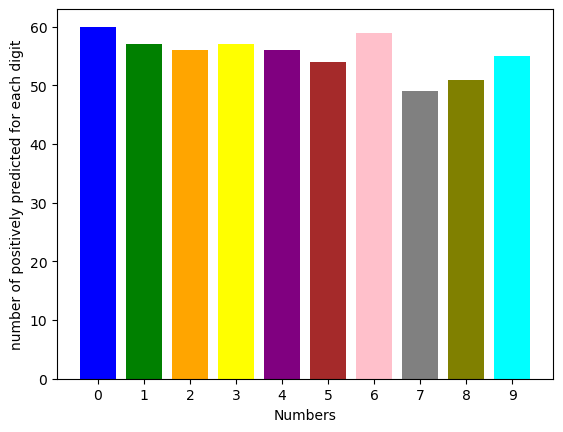

In [11]:
import matplotlib.pyplot as plt
means = []
for i, num in enumerate(number_of_positively_predicted_for_each_digit):
    print(f"the accuracy of predicting {i} is = {(value := (num / frequency_of_occurrence_of_each_number[i]) * 100):.2f}")
    means.append((num / frequency_of_occurrence_of_each_number[i]) * 100)
nms = [str(i) for i in range(10)]
c = ["blue", "green", "orange", "yellow", "purple", "brown", "pink", "gray", "olive", "cyan"]
plt.bar(nms, number_of_positively_predicted_for_each_digit, color=c)
plt.xlabel("Numbers")
plt.ylabel("number of positively predicted for each digit")
plt.savefig("number of positively predicted for each digit.jpg", dpi=2400)


In [12]:
distribtion_of_prediction_for_each_number = [[0 for _ in range(10)] for _ in range(10)]

for i in range(10):
    for j, digit in enumerate(real_val):
        if i == digit:
            distribtion_of_prediction_for_each_number[i][predicted[j]] += 1

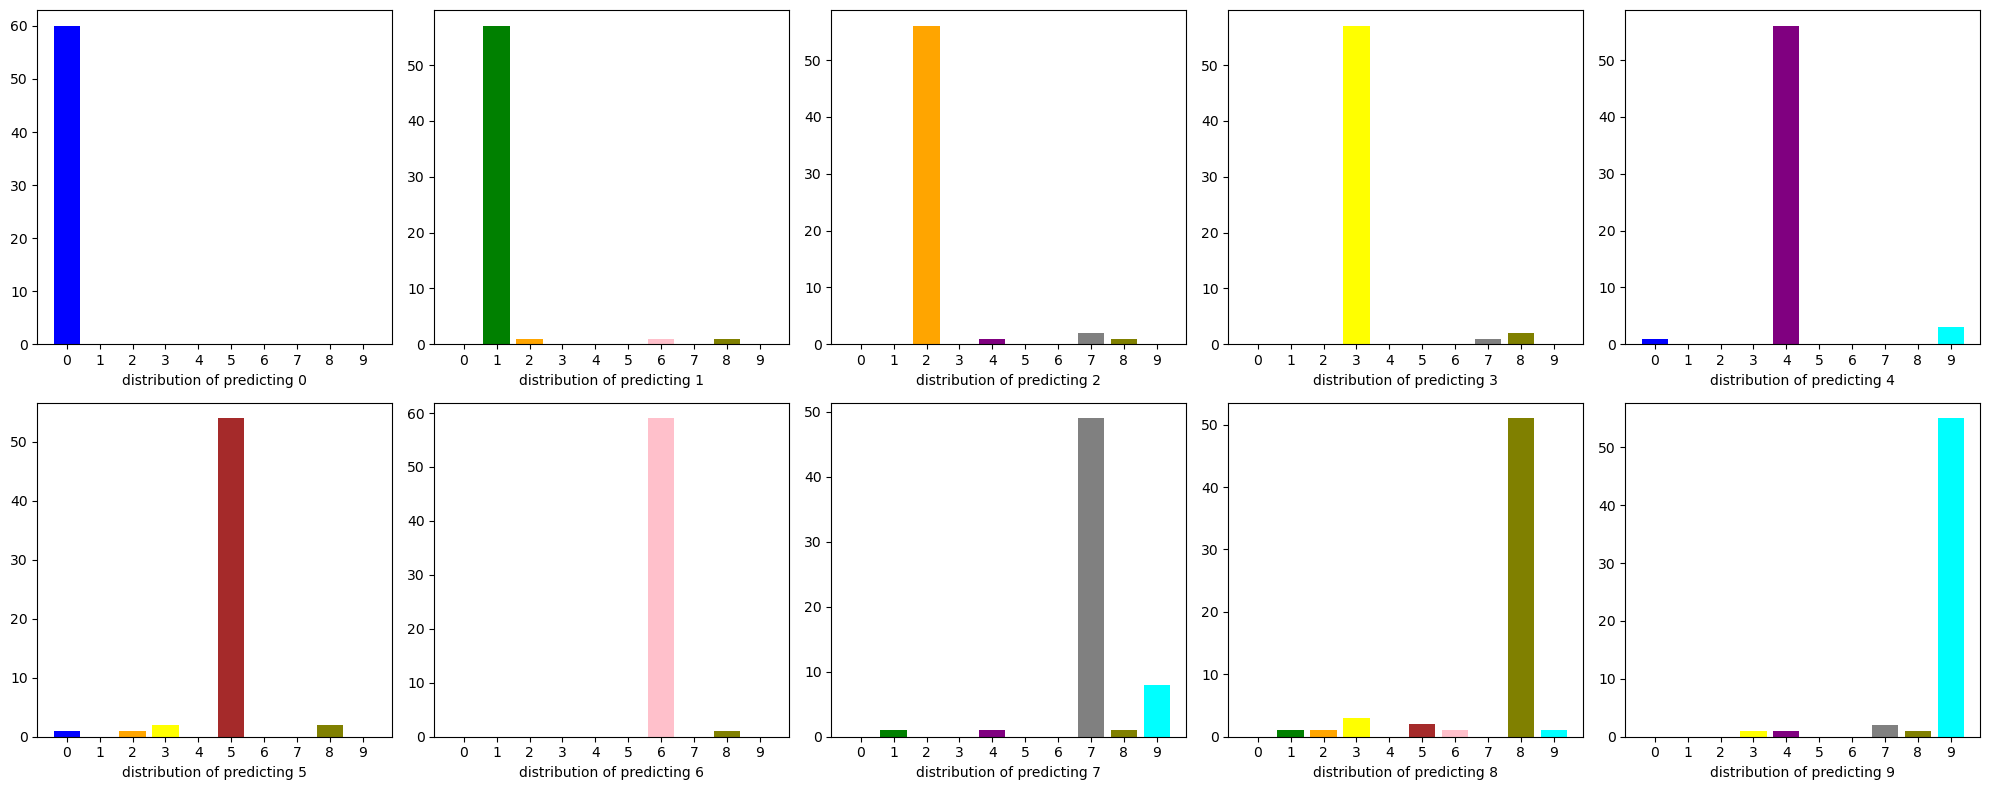

In [13]:
fig = plt.figure(figsize=(20, 8))
for i in range(len(distribtion_of_prediction_for_each_number)):
    fig.add_subplot(2 ,5 , i+1)
    plt.bar(nms, distribtion_of_prediction_for_each_number[i], color=c)
    plt.xlabel(f"distribution of predicting {i}")
plt.tight_layout()
plt.savefig("number of positively predicted for each digit.jpg", dpi=900)
plt.show()